# Resolution Filter

Plotting HeatFlux_kyst vs ky can be an identifier for resolution quality of the simulation. 

In [1]:
import src.pugs as pugs

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st

import netCDF4 as nc
import os
from glob import glob

In [2]:
folder = "/Users/zacharygottlieb/local/stellarator/data/20241119-01-008_200_configs"
file = "000089_theta0_3.14_zeta0_0.00/gx.out.nc"

file_path = os.path.join(folder, file)
print(file_path)

/Users/zacharygottlieb/local/stellarator/data/20241119-01-008_200_configs/000089_theta0_3.14_zeta0_0.00/gx.out.nc


In [7]:
ds = nc.Dataset(file_path, "r")
HeatFlux_kyst = ds["Diagnostics"]["HeatFlux_kyst"][:]
ky = ds["Grids"]["ky"][:]

In [8]:
_df = pugs.load_file(file_path, "HeatFlux_st")
start_time = pugs.steady_state(_df, "HeatFlux_st", method="linreg")
start_idx = np.where(_df["time"] >= start_time)[0][0]

In [9]:
data = {"ky": ky}
for i in range(len(HeatFlux_kyst)):
    data[f"HeatFlux_kyst_{i}"] = HeatFlux_kyst[i].flatten()
df = pd.DataFrame(data)

In [10]:
means = []
for i in range(len(df)):
    means.append(df.loc[i, f"HeatFlux_kyst_{start_idx}":].mean())
df.insert(1, "mean_HeatFlux_kyst", means)

mean_ky = ky[np.argmax(df["mean_HeatFlux_kyst"])]

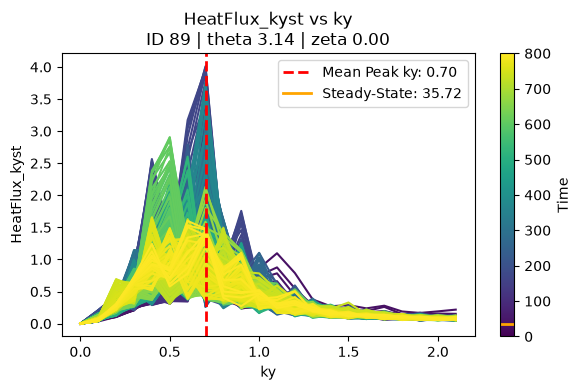

In [11]:
_ky = df["ky"].to_numpy()

fig, ax = plt.subplots(1, 1, figsize=(6,4))

colors = plt.cm.viridis(np.linspace(0, 1, len(HeatFlux_kyst)))

for i in range(len(HeatFlux_kyst)):
    if i < start_idx: continue
    _HeatFlux_kyst = df[f"HeatFlux_kyst_{i}"].to_numpy()
    ax.plot(_ky, _HeatFlux_kyst, color=colors[i])

sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(0, _df["time"][len(HeatFlux_kyst)-1]))
cbar = fig.colorbar(sm, ax=ax, label="Time")
cbar.ax.axhline(start_time, color="orange", lw=2, label=f"Steady-State: {start_time:.2f}")

ax.axvline(x=mean_ky, color="red", ls="--", lw=2, label=f"Mean Peak ky: {mean_ky:.2f}")

ax.set_xlabel("ky")
ax.set_ylabel("HeatFlux_kyst")
ax.set_title(f"HeatFlux_kyst vs ky\nID 89 | theta 3.14 | zeta 0.00")

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = cbar.ax.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2)

plt.tight_layout()
plt.show()

In [ ]:
start_df = pd.read_csv("heatflux_analysis/all_HeatFlux_st_linreg.csv")

def process_folder(folder):
    folders = sorted(glob(os.path.join(folder, "*_theta0_*_zeta0_*")))

    # Process each folder and colelct results
    results = []
    for f in folders:
        # Process individual GX file
        file = os.path.join(f, "gx.out.nc")

        # Extract experiment identification
        parts = os.path.basename(f).split("_")
        exp_info = {"id": parts[0], "theta": parts[2], "zeta": parts[4], "file": file}

        # Extract HeatFlux_kyst and ky
        ds = nc.Dataset(file, "r")
        HeatFlux_kyst = ds["Diagnostics"]["HeatFlux_kyst"][:]
        ky = ds["Grids"]["ky"][:]

        # Identify the steady-state start
        start_df["start_time"]
        start_time = start_df.loc[(start_df["file"] == exp_info["file"]), "start_time"].values[0]
        if pd.isna(start_time):
            start_idx = 0
        else:
            _df = pugs.load_file(file, "HeatFlux_st")
            start_idx = np.where(_df["time"] >= start_time)[0][0]

        # Create a DataFrame with the HeatFlux_kyst data
        data = {}
        for i in range(len(HeatFlux_kyst)):
            data[f"HeatFlux_kyst_{i}"] = HeatFlux_kyst[i].flatten()
        df = pd.DataFrame(data)

        # Find the mean HeatFlux_kyst for each ky starting from the steady-state index
        means = []
        for i in range(len(df)):
            means.append(df.loc[i, f"HeatFlux_kyst_{start_idx}":].mean())
        df["mean_HeatFlux_kyst"] = means
        
        # Compute mean ky to be peak of the mean HeatFlux_kyst
        mean_ky = ky[np.argmax(df["mean_HeatFlux_kyst"])]

        # Store results
        results.append({**exp_info,
            "ky": mean_ky,
            "start_time": start_time,
            "mean": start_df.loc[(start_df["file"] == exp_info["file"]), "mean"].values[0],
            "std": start_df.loc[(start_df["file"] == exp_info["file"]), "std"].values[0],})
    
    # Return results as a CSV
    return pd.DataFrame(results).to_csv("all_HeatFlux_kyst_mean_ky.csv", index=False)

In [16]:
df = process_folder(folder)

In [26]:
df = pd.read_csv("all_HeatFlux_kyst_mean_ky.csv")
df.head()

,id,theta,zeta,file,ky,start_time,mean,std
0,0,0.00,0.00,/Users/zacharygottlieb/local/stellarator/data/...,0.4,237.736137,0.345247,0.136988
1,0,0.00,1.57,/Users/zacharygottlieb/local/stellarator/data/...,1.1,NaN,NaN,NaN
2,0,3.14,0.00,/Users/zacharygottlieb/local/stellarator/data/...,0.5,13.144094,51.800823,6.691688
3,0,3.14,1.57,/Users/zacharygottlieb/local/stellarator/data/...,1.9,NaN,NaN,NaN
4,1,0.00,0.00,/Users/zacharygottlieb/local/stellarator/data/...,1.1,19.631783,55.760700,8.647595


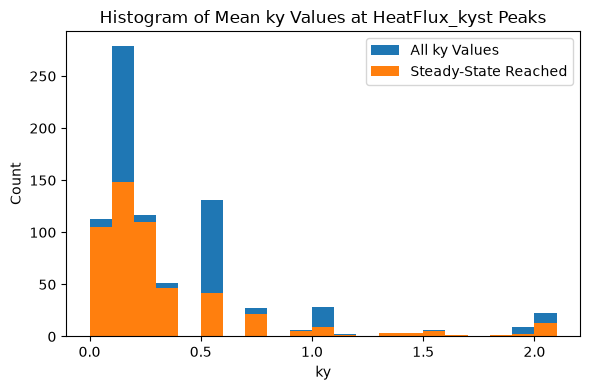

In [27]:
fig, ax = plt.subplots(1, 1, figsize=(6,4))

ax.hist(df["ky"], bins=ky, label="All ky Values")

ss_df = df[df["start_time"].notna()]
ax.hist(ss_df["ky"], bins=ky, label="Steady-State Reached")

ax.set_xlabel("ky")
ax.set_ylabel("Count")
ax.set_title("Histogram of Mean ky Values at HeatFlux_kyst Peaks")

ax.legend()
plt.tight_layout()
plt.show()

In [28]:
Q1 = df["ky"].quantile(0.25)
Q3 = df["ky"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

mask = df["ky"].between(lower, upper)

failed_df = df[~mask].copy()
df = df[mask].copy()
ss_df = df[df["start_time"].notna()]
ss_failed_df = failed_df[failed_df["start_time"].notna()]

print(f"{df.shape[0]} runs pass resolution filter")
print(f"{failed_df.shape[0]}  runs fail resolution filter")
print(f"{ss_df.shape[0]} runs pass filter and reaches steady-state")
print(f"{ss_failed_df.shape[0]}  runs fail filter and reaches steady-state")

724 runs pass resolution filter
76  runs fail resolution filter
479 runs pass filter and reaches steady-state
38  runs fail filter and reaches steady-state


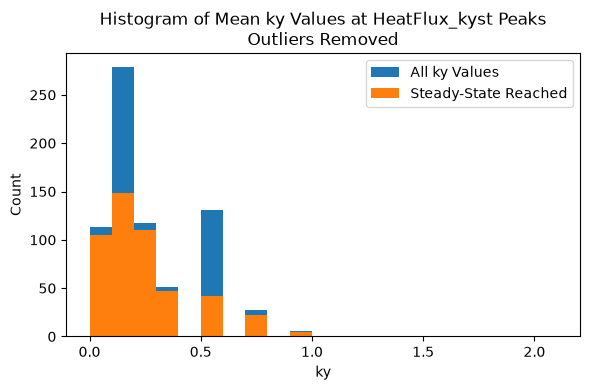

In [29]:
fig, ax = plt.subplots(1, 1, figsize=(6,4))

ax.hist(df["ky"], bins=ky, label="All ky Values")
ax.hist(ss_df["ky"], bins=ky, label="Steady-State Reached")

ax.set_xlabel("ky")
ax.set_ylabel("Count")
ax.set_title("Histogram of Mean ky Values at HeatFlux_kyst Peaks\nOutliers Removed")

ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
logx = np.log(ss_df["start_time"])
logy = np.log(ss_df["mean"])

slope, intercept, r_val, p_val, std_err = st.linregress(logx, logy)

print(f"Mean HeatFlux_st = {np.exp(intercept):.5f} * (Time to Steady-State)^({slope:.5f})")
print(f"R-squared: {r_val**2:.5f}")

Mean HeatFlux_st = 2849.46186 * (Time to Steady-State)^(-1.47157)
R-squared: 0.72175


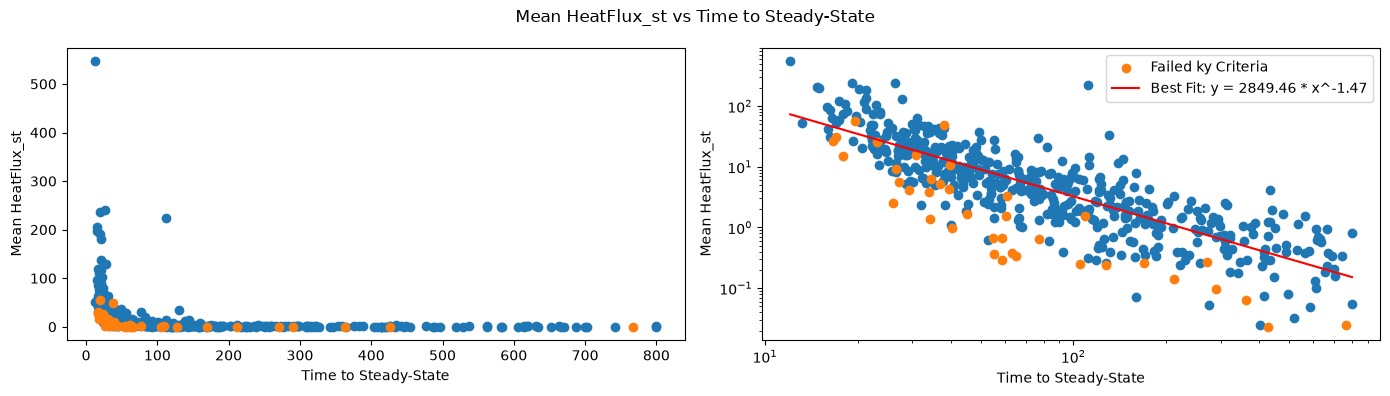

In [31]:
xline = np.linspace(ss_df["start_time"].min(), ss_df["start_time"].max(), 400)
yline = np.exp(intercept) * xline**slope

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for i, ax in enumerate(axes.flatten()):
    ax.scatter(ss_df["start_time"], ss_df["mean"])
    ax.scatter(ss_failed_df["start_time"], ss_failed_df["mean"], label="Failed ky Criteria")
    ax.set_xlabel("Time to Steady-State")
    ax.set_ylabel(f"Mean HeatFlux_st")

    if i == 1:
        ax.plot(xline, yline, color='red', label=f"Best Fit: y = {np.exp(intercept):.2f} * x^{slope:.2f}")
        ax.set_xscale("log")
        ax.set_yscale("log")

fig.suptitle(f"Mean HeatFlux_st vs Time to Steady-State")

plt.legend()
plt.tight_layout()
plt.show()

In [32]:
logx = np.log(ss_failed_df["start_time"])
logy = np.log(ss_failed_df["mean"])

residuals = logy - (slope * logx + intercept)
residuals = pd.DataFrame(np.abs(residuals), columns=["residuals"])
ss_failed_df["residuals"] = residuals["residuals"]

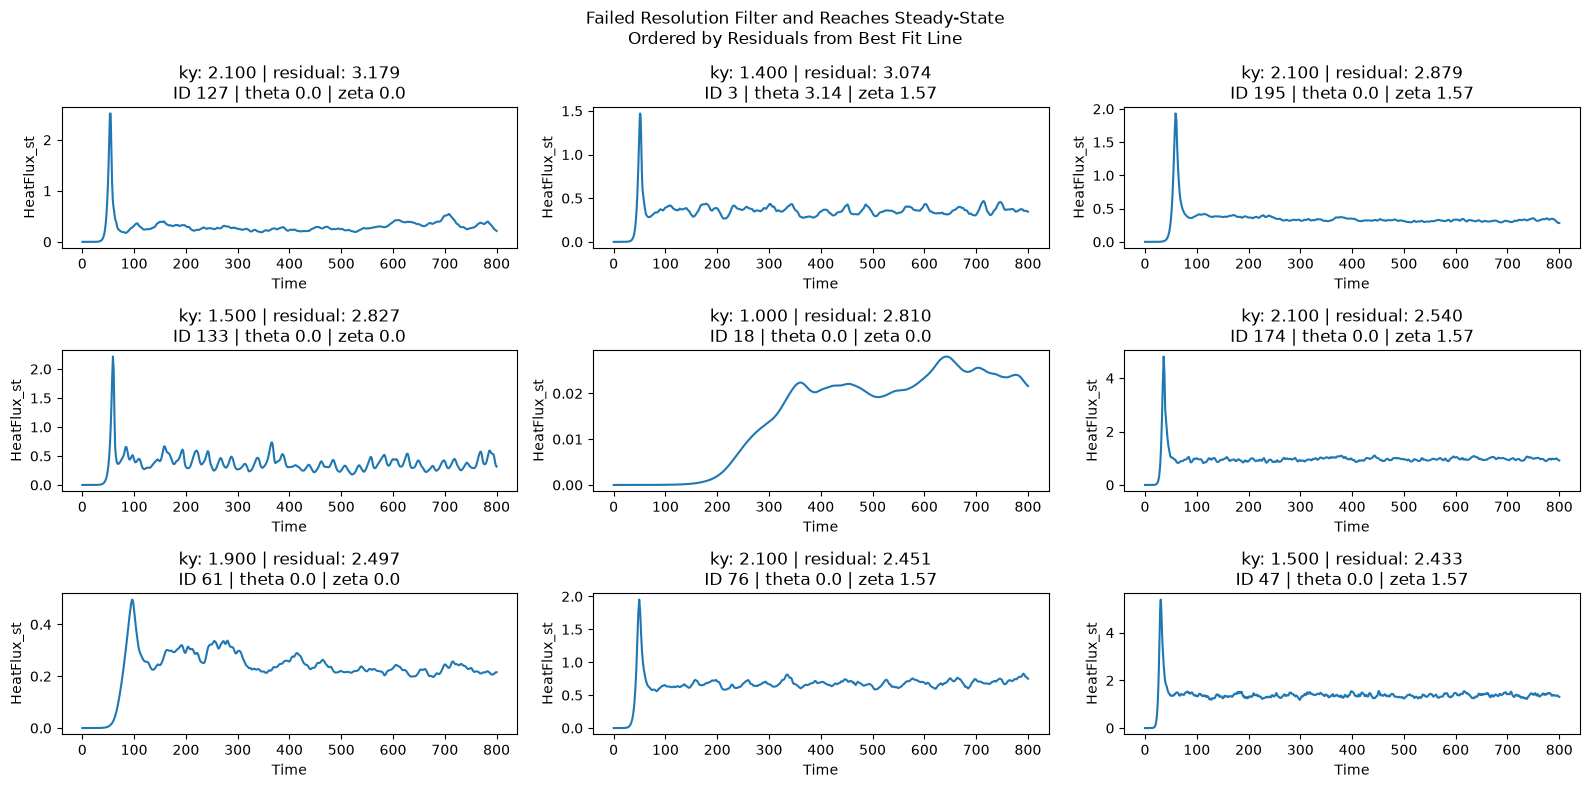

In [33]:
ss_failed_df = ss_failed_df.sort_values(by="residuals", ascending=False)

fig, axes = plt.subplots(3, 3, figsize=(16,8))

for i, ax in enumerate(axes.flatten()):
    df_i = pugs.load_file(ss_failed_df.iloc[i]["file"], "HeatFlux_st")
    t = df_i["time"].to_numpy()
    x = df_i["HeatFlux_st"].to_numpy()

    ax.plot(t, x)

    ax.set_title(f"ky: {ss_failed_df.iloc[i]['ky']:.3f} | residual: {ss_failed_df.iloc[i]['residuals']:.3f}\nID {ss_failed_df.iloc[i]['id']} | theta {ss_failed_df.iloc[i]['theta']} | zeta {ss_failed_df.iloc[i]['zeta']}")
    ax.set_xlabel("Time")
    ax.set_ylabel("HeatFlux_st")

fig.suptitle(f"Failed Resolution Filter and Reaches Steady-State\nOrdered by Residuals from Best Fit Line")

plt.tight_layout()
plt.show()

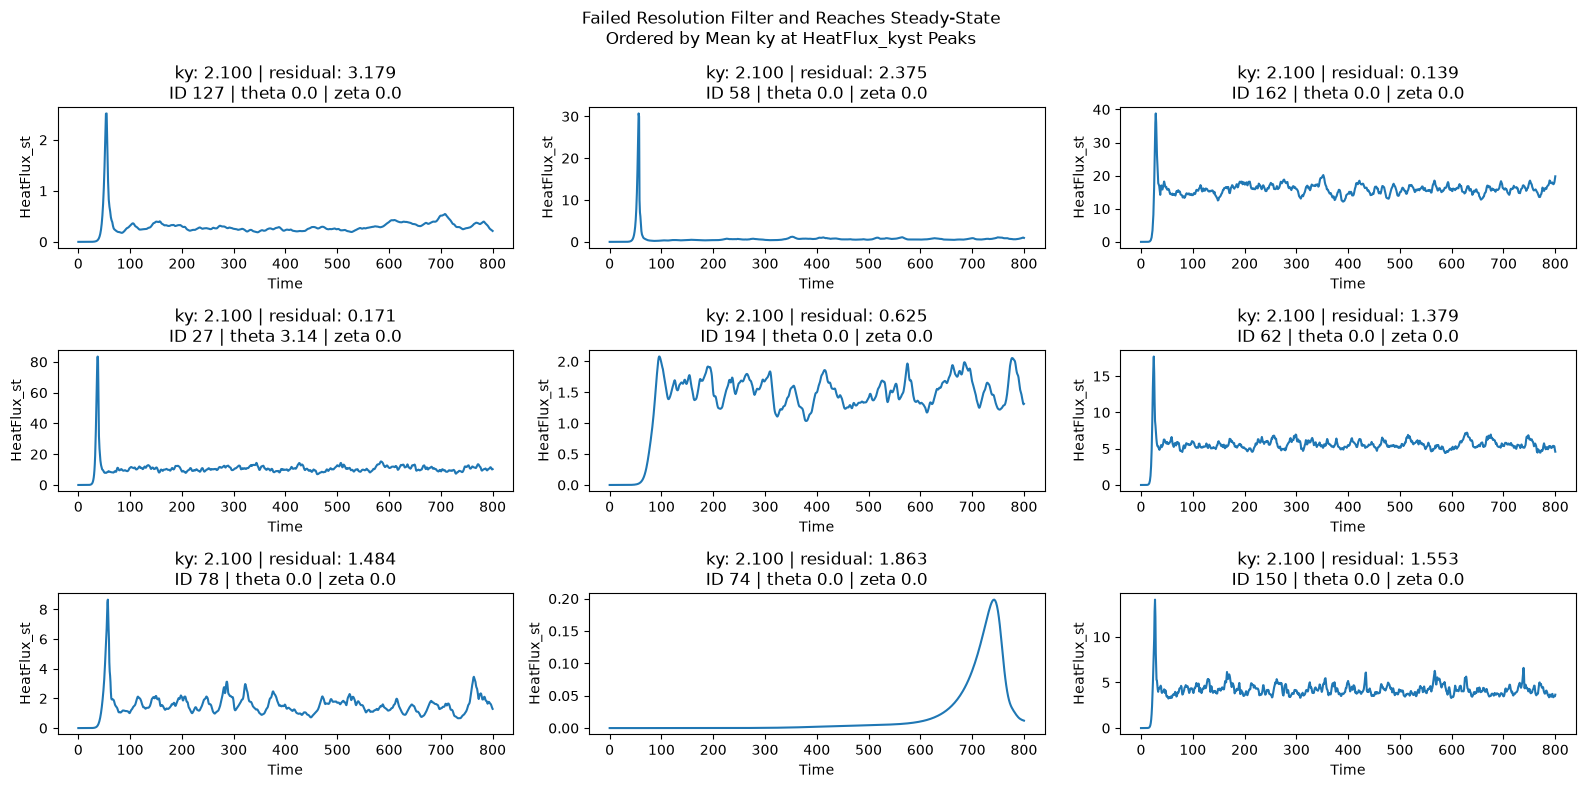

In [34]:
ss_failed_df = ss_failed_df.sort_values(by="ky", ascending=False)

fig, axes = plt.subplots(3, 3, figsize=(16,8))

for i, ax in enumerate(axes.flatten()):
    df_i = pugs.load_file(ss_failed_df.iloc[i]["file"], "HeatFlux_st")
    t = df_i["time"].to_numpy()
    x = df_i["HeatFlux_st"].to_numpy()

    ax.plot(t, x)

    ax.set_title(f"ky: {ss_failed_df.iloc[i]['ky']:.3f} | residual: {ss_failed_df.iloc[i]['residuals']:.3f}\nID {ss_failed_df.iloc[i]['id']} | theta {ss_failed_df.iloc[i]['theta']} | zeta {ss_failed_df.iloc[i]['zeta']}")
    ax.set_xlabel("Time")
    ax.set_ylabel("HeatFlux_st")

fig.suptitle(f"Failed Resolution Filter and Reaches Steady-State\nOrdered by Mean ky at HeatFlux_kyst Peaks")

plt.tight_layout()
plt.show()